In [1]:
import anndata
import scanpy as sc
import matplotlib.pyplot as plt
from matplotlib import colormaps
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize
import pandas as pd
import numpy as np
from scanpy import plotting as pl
from adjustText import adjust_text
from scipy.stats import binom, false_discovery_control
from matplotlib.collections import PathCollection
import seaborn as sns
from io import StringIO

In [2]:
def load_arial(arial_folder_path):
    from pathlib import Path
    from matplotlib import font_manager, rcParams
    for font_path in Path(arial_folder_path).glob('*.TTF'):
        font_manager.fontManager.addfont(str(font_path))

    arial_n = {'fontproperties':font_manager.FontProperties(fname="misc/arial/ARIALN.TTF")}
    arial_nb = {'fontproperties':font_manager.FontProperties(fname="misc/arial/ARIALNB.TTF")}

    assert 'Arial' in [f.name for f in font_manager.fontManager.ttflist]

    rcParams['font.family'] = 'sans-serif'
    rcParams['font.sans-serif'] = ['Arial']
    rcParams['ps.fonttype'] = 42
    rcParams['pdf.fonttype'] = 42

    rcParams['mathtext.fontset'] = 'custom'
    rcParams['mathtext.rm'] = 'Arial'
    rcParams['mathtext.it'] = 'Arial:italic'
    rcParams['mathtext.bf'] = 'Arial:bold'

    return arial_n, arial_nb
load_arial('/stor/home/tms4478/work/Arial')

({'fontproperties': <matplotlib.font_manager.FontProperties at 0x76de39efff40>},
 {'fontproperties': <matplotlib.font_manager.FontProperties at 0x76de39effdc0>})

In [3]:
ad_hk177 = sc.read_h5ad('HK177_02_new.h5ad')
ad_hk177.X = ad_hk177.layers['OLD_X'].copy()
ad_hk177 = ad_hk177[:, np.mean(ad_hk177.X != 0., axis=0) > 0.1]
ad_hk177.obs['cell_line'] ='HK177'

/tmp/ipykernel_2346051/2188106948.py:4: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  ad_hk177.obs['cell_line'] ='HK177'


In [4]:
ad_gs54 = sc.read_h5ad('GS54_cleaned.h5ad')
ad_gs54.X = ad_gs54.layers['norm_counts']
ad_gs54 = ad_gs54[:, np.mean(ad_gs54.X != 0., axis=0) > 0.1]
ad_gs54.obs['cell_line'] ='GS54'
ad_gs54

/tmp/ipykernel_2346051/3487811760.py:4: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  ad_gs54.obs['cell_line'] ='GS54'


AnnData object with n_obs × n_vars = 4943 × 3289
    obs: 'sample', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'outlier', 'doublet_score', 'predicted_doublets', 'S_score', 'G2M_score', 'phase', 'cc_difference', 'cell_line'
    var: 'gene_ids', 'feature_types', 'genome', 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells'
    uns: 'Processing', 'log1p', 'sample_colors'
    layers: 'cc_regressed', 'counts', 'cpm', 'norm_counts'

In [5]:
hk177_genes = ad_hk177.var_names
gs54_genes = ad_gs54.var_names
common_genes = hk177_genes.intersection(gs54_genes)

In [6]:
common_ad_hk177 = ad_hk177[:, common_genes].copy()
common_ad_hk177 = sc.pp.scale(common_ad_hk177, copy=True)

In [7]:
common_ad_gs54 = ad_gs54[:, common_genes].copy()
common_ad_gs54 

AnnData object with n_obs × n_vars = 4943 × 2783
    obs: 'sample', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'outlier', 'doublet_score', 'predicted_doublets', 'S_score', 'G2M_score', 'phase', 'cc_difference', 'cell_line'
    var: 'gene_ids', 'feature_types', 'genome', 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells'
    uns: 'Processing', 'log1p', 'sample_colors'
    layers: 'cc_regressed', 'counts', 'cpm', 'norm_counts'

In [8]:
scale_ad_gs54 = sc.pp.scale(common_ad_gs54, copy=True)
scale_ad_gs54

AnnData object with n_obs × n_vars = 4943 × 2783
    obs: 'sample', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'outlier', 'doublet_score', 'predicted_doublets', 'S_score', 'G2M_score', 'phase', 'cc_difference', 'cell_line'
    var: 'gene_ids', 'feature_types', 'genome', 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'mean', 'std'
    uns: 'Processing', 'log1p', 'sample_colors'
    layers: 'cc_regressed', 'counts', 'cpm', 'norm_counts'

In [9]:
ad_combined = common_ad_hk177.concatenate(scale_ad_gs54, batch_key='sample_id', batch_categories=['HK177', 'GS54'], index_unique=None)
ad_combined

/tmp/ipykernel_2346051/4264658049.py:1: FutureWarning: Use anndata.concat instead of AnnData.concatenate, AnnData.concatenate is deprecated and will be removed in the future. See the tutorial for concat at: https://anndata.readthedocs.io/en/latest/concatenation.html
  ad_combined = common_ad_hk177.concatenate(scale_ad_gs54, batch_key='sample_id', batch_categories=['HK177', 'GS54'], index_unique=None)


AnnData object with n_obs × n_vars = 8793 × 2783
    obs: 'sample', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'outlier', 'doublet_score', 'predicted_doublets', 'lineage', 'S_score', 'G2M_score', 'phase', 'cc_difference', 'leiden_res0_25', 'leiden_res0_5', 'leiden_res1', 'phenotype', 'cell_line', 'sample_id'
    var: 'gene_ids', 'feature_types', 'genome', 'mt', 'ribo', 'hb', 'n_cells_by_counts-GS54', 'mean_counts-GS54', 'log1p_mean_counts-GS54', 'pct_dropout_by_counts-GS54', 'total_counts-GS54', 'log1p_total_counts-GS54', 'n_cells-GS54', 'mean-GS54', 'std-GS54', 'n_cells_by_counts-HK177', 'mean_counts-HK177', 'log1p_mean_counts-HK177', 'pct_dropout_by_counts-HK177', 'total_counts-HK177', 'log1p_total_counts-HK177', 'n_cells-HK17

In [10]:
ad_combined.uns['sample_colors']=['#440154ff','#22a884ff','#b22222','#4169e1']

In [11]:
ad_combined.obs['phenotype']

AAACCCACACGTAACT-1       
AAACGCTAGCACTAGG-1       
AAACGCTCATTGGCAT-1       
AAACGCTGTAATGATG-1       
AAACGCTTCACATACG-1       
                     ... 
TGTCGTCCAACTATCT-4    NaN
TGTCGTCCACTTCACA-4    NaN
TGTCTCACATGAATTG-4    NaN
TGTCTTGCAAGTATCA-4    NaN
TGTGAACCATTAGACA-4    NaN
Name: phenotype, Length: 8793, dtype: category
Categories (3, object): ['', 'migratory', 'nonmigratory']

In [12]:
anndata.AnnData.write(ad_combined, 'combined-cell-lines_ad.h5ad')

In [13]:
ad_combined.obs['sample_name'] = ad_combined.obs['sample'].map({
    'SoftMi':'Soft$\\rightarrow$Soft Migrating',
    'SoftNon': 'Soft$\\rightarrow$Soft Non-Migrating',
    'StiffMi': 'Stiff$\\rightarrow$Soft Migrating',
    'StiffNon':'Stiff$\\rightarrow$Soft Non-Migrating'
    })

# Load MAST Datasets

In [14]:
stiff_vs_soft = pd.read_csv('mast_combined/combined_stiff_vs_soft.csv', index_col=0)
softmi_vs_softnon = pd.read_csv('mast_combined/combined_softmi_vs_softnon.csv', index_col=0)
stiffmi_vs_softmi = pd.read_csv('mast_combined/combined_stiffmi_vs_softmi.csv', index_col=0)
stiffmi_vs_stiffnon = pd.read_csv('mast_combined/combined_stiffmi_vs_stiffnon.csv', index_col=0)
stiffnon_vs_softnon = pd.read_csv('mast_combined/combined_stiffnon_vs_softnon.csv', index_col=0)
top_vs_bottom = pd.read_csv('mast_combined/combined_top_vs_bottom.csv', index_col=0)

In [15]:
misubp_vs_nonmisubp = pd.read_csv('mast_hk177/misubp_vs_nonmisubp.csv', index_col=0)

In [16]:
p_cutoff = 0.0005
lfc_cutoff = 0.25

# Gene Analysis

In [17]:
top_vs_bottom.loc[(top_vs_bottom['FDR'] < p_cutoff) & (np.abs(top_vs_bottom['coef']) > lfc_cutoff), :].sort_values('coef')

,Pr(>Chisq),coef,FDR
primerid,,,
SPARC,9.004980e-243,-1.007772,2.506086e-239
CRYAB,7.898043e-153,-0.609775,7.326751e-150
MALAT1,1.291451e-75,-0.471356,1.497545e-73
SOX4,5.189807e-81,-0.448326,8.024018e-79
RRBP1,4.377491e-100,-0.403406,1.218256e-97
...,...,...,...
H2AFZ,1.264888e-63,0.430950,8.585810e-62
FAM162A,4.749054e-106,0.448383,2.202770e-103
FBLN1,4.982450e-62,0.453624,3.014382e-60


In [18]:
top_vs_bottom.loc['LGALS1']

Pr(>Chisq)    4.921737e-80
coef          3.646140e-01
FDR           7.209050e-78
Name: LGALS1, dtype: float64

In [19]:
stiffmi_vs_stiffnon.loc[(stiffmi_vs_stiffnon['FDR'] < p_cutoff) & (np.abs(stiffmi_vs_stiffnon['coef']) > lfc_cutoff), :].sort_values('coef')

,Pr(>Chisq),coef,FDR
primerid,,,
SPARC,9.498045e-238,-1.641089,2.643306e-234
FOS,1.260342e-142,-1.047622,1.169177e-139
ATF3,2.701289e-108,-0.899163,1.073955e-105
AHNAK,5.725377e-88,-0.777830,1.138123e-85
RRBP1,1.847023e-122,-0.706366,1.028053e-119
...,...,...,...
ERO1A,3.814773e-47,0.549362,2.793819e-45
GAPDH,8.430492e-109,0.560323,3.910343e-106
BNIP3,4.284300e-57,0.648135,4.258288e-55


In [20]:
misubp_vs_nonmisubp.loc[(misubp_vs_nonmisubp['FDR'] < p_cutoff) & ((misubp_vs_nonmisubp['coef']) > lfc_cutoff)]

,Pr(>Chisq),coef,FDR
primerid,,,
AKR1B1,1.069987e-10,0.325298,1.175550e-08
ANKRD11,1.049072e-10,0.318151,1.166801e-08
APRT,7.729641e-17,0.415285,1.698447e-14
ARL2BP,9.734664e-24,0.433927,5.846639e-21
ATP6V0D1,1.777084e-16,0.316003,3.557721e-14
...,...,...,...
TMEM208,2.367279e-10,0.275935,2.396272e-08
TRIO,1.017719e-06,0.261499,5.361770e-05
TUBB3,3.271489e-18,0.457851,9.210265e-16


In [21]:
genes_of_intrest = misubp_vs_nonmisubp.loc[
    misubp_vs_nonmisubp.loc[(misubp_vs_nonmisubp['FDR'] < p_cutoff) & ((misubp_vs_nonmisubp['coef']) > lfc_cutoff), :].index.intersection(
    top_vs_bottom.loc[(top_vs_bottom['FDR'] < p_cutoff) & ((top_vs_bottom['coef']) > lfc_cutoff), :].index)]

genes_of_intrest

,Pr(>Chisq),coef,FDR
primerid,,,
LGALS1,4.087093e-09,0.255128,3.409317e-07
NAMPT,3.296714e-08,0.265411,2.414642e-06


findfont: Font family ['cursive'] not found. Falling back to DejaVu Sans.
findfont: Generic family 'cursive' not found because none of the following families were found: Apple Chancery, Textile, Zapf Chancery, Sand, Script MT, Felipa, Comic Neue, Comic Sans MS, cursive


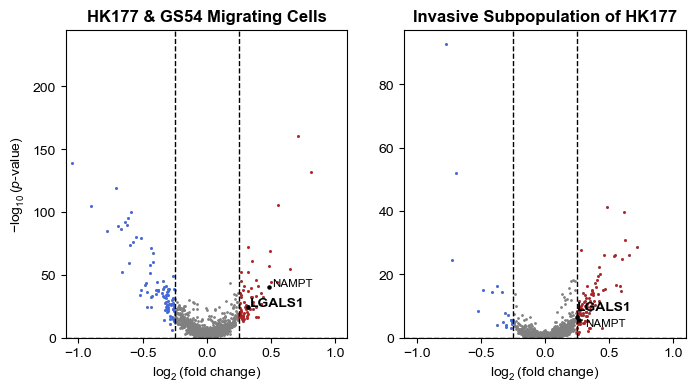

In [22]:
lfc_cutoff=0.25
coef =0.00005

fig, axs = plt.subplots(1, 2, figsize=(8, 4))
axs[0].scatter(
    stiffmi_vs_stiffnon['coef'],
    -np.log10(stiffmi_vs_stiffnon['FDR']),
    s=1, color='grey'
)

axs[1].scatter(
    misubp_vs_nonmisubp['coef'],
    -np.log10(misubp_vs_nonmisubp['FDR']),
    s=1, color='grey'
)

axs[0].set_ylabel('$-\log_{10}(p$-value$)$')

axs[0].set_xlim(-1*1.1, 1*1.1)
axs[1].set_xlim(-1*1.1, 1*1.1)

for ax in axs:
    ax.set_xlabel('$\\log_2($fold change$)$')
    ax.set_ylim((0, ax.get_ylim()[1]))
    ax.vlines([-lfc_cutoff, lfc_cutoff], ax.get_ylim()[0], ax.get_ylim()[1], color='black', linestyles='--', alpha=1., linewidth=1)
    ax.hlines(p_cutoff, ax.get_xlim()[0], ax.get_xlim()[1], color='black', linestyles='--', alpha=1., linewidth=1)

axs[0].set_title('HK177 & GS54 Migrating Cells', fontweight='bold')
axs[1].set_title('Invasive Subpopulation of HK177', fontweight='bold')

anns1 = []
anns2 = []

for gene in stiffmi_vs_stiffnon.index:
    if stiffmi_vs_stiffnon.loc[gene, 'coef'] > lfc_cutoff:
        axs[0].scatter(
            stiffmi_vs_stiffnon.loc[gene, 'coef'],
            -np.log10(stiffmi_vs_stiffnon.loc[gene, 'FDR']),
            color='firebrick', s=1
        )
    if stiffmi_vs_stiffnon.loc[gene, 'coef'] < -lfc_cutoff:
        axs[0].scatter(
            stiffmi_vs_stiffnon.loc[gene, 'coef'],
            -np.log10(stiffmi_vs_stiffnon.loc[gene, 'FDR']),
            color='royalblue', s=1
        )
for gene in misubp_vs_nonmisubp.index:
    if misubp_vs_nonmisubp.loc[gene, 'coef'] > lfc_cutoff:
        axs[1].scatter(
            misubp_vs_nonmisubp.loc[gene, 'coef'],
            -np.log10(misubp_vs_nonmisubp.loc[gene, 'FDR']),
            color='firebrick', s=1
        )
    if misubp_vs_nonmisubp.loc[gene, 'coef'] < -lfc_cutoff:
        axs[1].scatter(
            misubp_vs_nonmisubp.loc[gene, 'coef'],
            -np.log10(misubp_vs_nonmisubp.loc[gene, 'FDR']),
            color='royalblue', s=1
        )

for gene in genes_of_intrest.index:
    axs[0].scatter(
        stiffmi_vs_stiffnon.loc[gene, 'coef'],
        -np.log10(stiffmi_vs_stiffnon.loc[gene, 'FDR']),
        color='black', s=5
    )
    axs[1].scatter(
        misubp_vs_nonmisubp.loc[gene, 'coef'],
        -np.log10(misubp_vs_nonmisubp.loc[gene, 'FDR']),
        color='black', s=5
    )
        
    if gene == 'LGALS1':
        anns1.append(axs[0].text(
            stiffmi_vs_stiffnon.loc[gene, 'coef'],
            -np.log10(stiffmi_vs_stiffnon.loc[gene, 'FDR']),
            gene, fontweight='bold'
        ))
        anns2.append(axs[1].text(
            misubp_vs_nonmisubp.loc[gene, 'coef'],
            -np.log10(misubp_vs_nonmisubp.loc[gene, 'FDR']),
            gene, fontweight='bold'
        ))
    else:
        anns1.append(axs[0].text(
            stiffmi_vs_stiffnon.loc[gene, 'coef'],
            -np.log10(stiffmi_vs_stiffnon.loc[gene, 'FDR']),
            gene, fontweight='regular', size = 'small'
        ))
        anns2.append(axs[1].text(
            misubp_vs_nonmisubp.loc[gene, 'coef'],
            -np.log10(misubp_vs_nonmisubp.loc[gene, 'FDR']),
            gene, fontweight='regular', size = 'small'
        ))

adjust_text(anns1, arrowprops=dict(linewidth=1, color='black', alpha=0.7), ax=axs[0])
adjust_text(anns2, arrowprops=dict(linewidth=1, color='black', alpha=0.7), ax=axs[1])

plt.savefig('figures/LGALS1_volcanoplot_subpop-combinedsamples.svg', bbox_inches='tight')

## Stiffness on Non-migratory cells

In [23]:
p_cutoff =  0.00005
lfc_cutoff = 0.6

In [24]:
stiffnon_vs_softnon.loc[(stiffnon_vs_softnon['FDR'] < p_cutoff) & (np.abs(stiffnon_vs_softnon['coef']) > lfc_cutoff), :].sort_values('coef')

,Pr(>Chisq),coef,FDR
primerid,,,
DDIT4,6.463805e-111,-0.738042,1.798877e-108
VEGFA,8.268553e-66,-0.716565,1.000495e-63
ANKRD28,1.233715e-76,0.601252,2.019663e-74
MYC,8.478805e-61,0.612020,7.865505e-59
LMNA,2.072441e-82,0.662717,4.119718e-80
FOSB,1.174475e-72,0.682474,1.815869e-70
DDX5,3.851250e-137,0.694759,1.531147e-134
VIM,1.321009e-137,0.771586,6.127281e-135
AHNAK,1.062375e-114,0.855319,3.695737e-112


In [25]:
['#440154ff','#22a884ff','#b22222','#4169e1']

['#440154ff', '#22a884ff', '#b22222', '#4169e1']

Text(0, 0.5, '')

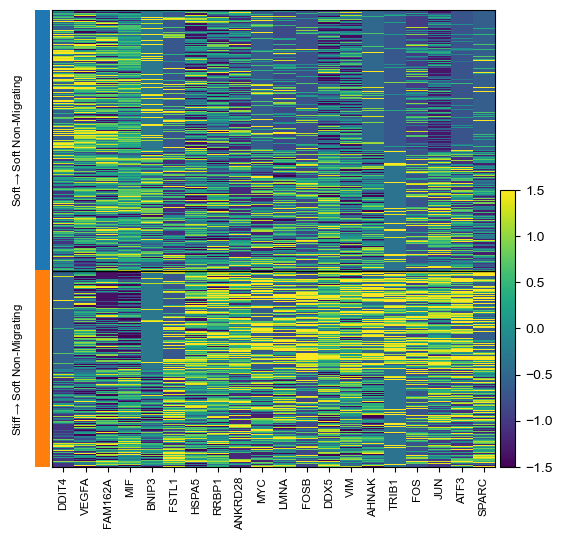

In [26]:
p_cutoff = 0.00005
lfc_cutoff = 0.5

axs = sc.pl.heatmap(sc.pp.scale(ad_combined[np.logical_or(ad_combined.obs['sample'] == 'StiffNon', ad_combined.obs['sample'] == 'SoftNon')], copy=True),
    var_names=stiffnon_vs_softnon.loc[(stiffnon_vs_softnon['FDR'] < p_cutoff) & (np.abs(stiffnon_vs_softnon['coef']) > lfc_cutoff), :].sort_values('coef').index,
    groupby='sample_name',
    vmax=1.5, vmin=-1.5,
    cmap='viridis',
    swap_axes=False,
    show = False
    #dendrogram=True
)
axs['groupby_ax'].set_yticks(axs['groupby_ax'].get_yticks(), axs['groupby_ax'].get_yticklabels(), rotation=90, ha='right', va='center')
axs['groupby_ax'].set_ylabel('')
#plt.savefig('stiffnon_v_softnon_combined_heatmap.svg',  bbox_inches='tight')


/stor/home/tms4478/miniconda3/envs/scrna/lib/python3.10/site-packages/scanpy/plotting/_dotplot.py:168: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  obs_bool.groupby(level=0).sum() / obs_bool.groupby(level=0).count()
/stor/home/tms4478/miniconda3/envs/scrna/lib/python3.10/site-packages/scanpy/plotting/_dotplot.py:178: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  dot_color_df = self.obs_tidy.groupby(level=0).mean()
/stor/home/tms4478/miniconda3/envs/scrna/lib/python3.10/site-packages/scanpy/plotting/_dotplot.py:747: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be igno

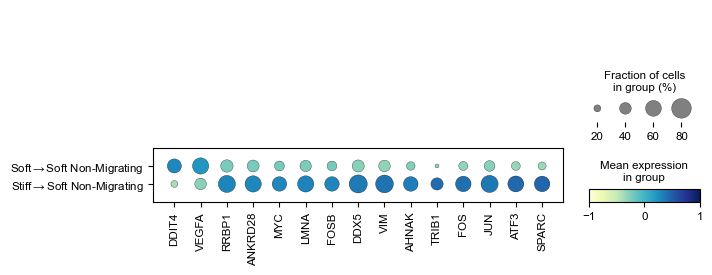

In [27]:
p_cutoff = 0.00005
lfc_cutoff = 0.58

axs= sc.pl.dotplot(
    sc.pp.scale(ad_combined[np.logical_or(ad_combined.obs['sample'] == 'StiffNon', ad_combined.obs['sample'] == 'SoftNon')], copy=True),
    #ad_hk177[np.logical_or(ad_hk177.obs['sample'] == 'StiffNon', ad_hk177.obs['sample'] == 'SoftNon')],
    var_names=stiffnon_vs_softnon.loc[(stiffnon_vs_softnon['FDR'] < p_cutoff) & (np.abs(stiffnon_vs_softnon['coef']) > lfc_cutoff), :].sort_values('coef').index,
    groupby='sample_name',
    vmax=1, vmin=-1,
    cmap='YlGnBu',
    swap_axes=False,
    dendrogram=True,
    show=False
)
#plt.savefig('stiffnon_v_softnon_combined_dotplot.svg',  bbox_inches='tight')

In [28]:
p_cutoff = 0.00005
lfc_cutoff = 0.7

stiffnon_vs_softnon_plot = stiffnon_vs_softnon.loc[(stiffnon_vs_softnon['FDR'] < p_cutoff) & (np.abs(stiffnon_vs_softnon['coef']) > lfc_cutoff), :].sort_values('coef')

In [29]:
stiffnon_vs_softnon_plot.index

Index(['DDIT4', 'VEGFA', 'VIM', 'AHNAK', 'TRIB1', 'FOS', 'JUN', 'ATF3',
       'SPARC'],
      dtype='object', name='primerid')

/stor/home/tms4478/miniconda3/envs/scrna/lib/python3.10/site-packages/scanpy/plotting/_anndata.py:839: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.violinplot(
/stor/home/tms4478/miniconda3/envs/scrna/lib/python3.10/site-packages/scanpy/plotting/_anndata.py:839: FutureWarning: 

The `scale` parameter has been renamed and will be removed in v0.15.0. Pass `density_norm='width'` for the same effect.
  ax = sns.violinplot(
/stor/home/tms4478/miniconda3/envs/scrna/lib/python3.10/site-packages/scanpy/plotting/_anndata.py:839: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.violinplot(
/stor/home/tms4478/miniconda3/envs/scrna/lib/python3.10/site-packages/scanpy/plotting/_anndata.py:839: FutureWarning: 


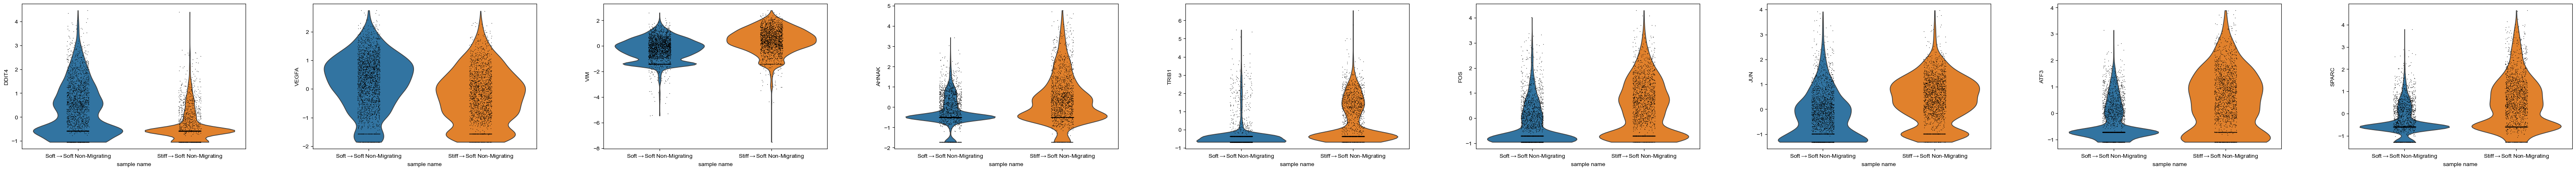

In [30]:
sc.pl.violin(sc.pp.scale(ad_combined[np.logical_or(ad_combined.obs['sample'] == 'StiffNon', ad_combined.obs['sample'] == 'SoftNon')], copy=True),
             groupby='sample_name',
             keys=stiffnon_vs_softnon_plot.index,
             multi_panel=True
             )

In [31]:
ax.get_xticklabels()[0].get_text().replace('$S', '$\nS')

'−1.5'

/stor/home/tms4478/miniconda3/envs/scrna/lib/python3.10/site-packages/scanpy/plotting/_anndata.py:839: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.violinplot(
/stor/home/tms4478/miniconda3/envs/scrna/lib/python3.10/site-packages/scanpy/plotting/_anndata.py:839: FutureWarning: 

The `scale` parameter has been renamed and will be removed in v0.15.0. Pass `density_norm='width'` for the same effect.
  ax = sns.violinplot(
/stor/home/tms4478/miniconda3/envs/scrna/lib/python3.10/site-packages/scanpy/plotting/_anndata.py:839: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.violinplot(
/stor/home/tms4478/miniconda3/envs/scrna/lib/python3.10/site-packages/scanpy/plotting/_anndata.py:839: FutureWarning: 


/stor/home/tms4478/miniconda3/envs/scrna/lib/python3.10/site-packages/scanpy/plotting/_anndata.py:839: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.violinplot(
/stor/home/tms4478/miniconda3/envs/scrna/lib/python3.10/site-packages/scanpy/plotting/_anndata.py:839: FutureWarning: 

The `scale` parameter has been renamed and will be removed in v0.15.0. Pass `density_norm='width'` for the same effect.
  ax = sns.violinplot(
/stor/home/tms4478/miniconda3/envs/scrna/lib/python3.10/site-packages/scanpy/plotting/_anndata.py:839: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.violinplot(
/stor/home/tms4478/miniconda3/envs/scrna/lib/python3.10/site-packages/scanpy/plotting/_anndata.py:839: FutureWarning: 


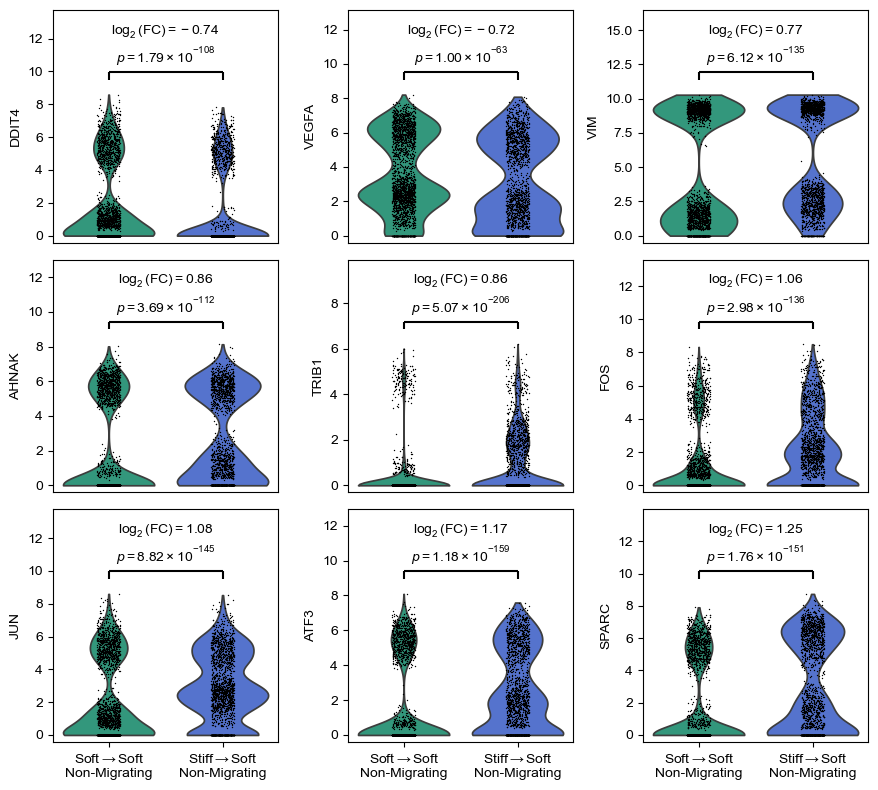

In [32]:
fig, axes = plt.subplots(3, 3, figsize=(9, 8))

for i, gene in enumerate(stiffnon_vs_softnon_plot.index):
    ax = axes[i//3, i%3]

    sc.pl.violin(
        sc.pp.scale(ad_combined[np.logical_or(ad_combined.obs['sample'] == 'StiffNon', ad_combined.obs['sample'] == 'SoftNon')], copy=True),
        keys=gene,
        groupby="sample_name",
        layer='norm_counts',
        ax=ax,
        palette= ['#22a884ff','#4169e1'],
        show=False,
    )

    if i < 6:
        ax.set_xticks([])
    else:
        ax.set_xticklabels([label.get_text().replace('t ', 't\n') for label in ax.get_xticklabels()])
    ax.set_xlabel("")

    lfc = stiffnon_vs_softnon.at[gene, 'coef']
    lfc = f'{lfc:.2f}'
    p = stiffnon_vs_softnon.at[gene, 'FDR']
    p = str(p).split('e')[0][:4]+' \\times 10^{'+str(p).split('e')[1]+'}'

    # make significance bars
    ymin = ax.get_ylim()[0]
    ymax = ax.get_ylim()[1]
    ax.hlines(ymax+(ymax-ymin)*0.1, 0, 1, colors='black')
    ax.vlines([0, 1], ymax+(ymax-ymin)*0.05, ymax+(ymax-ymin)*0.1, colors='black')
    ax.text(0.5, ymax+(ymax-ymin)*0.12, 
            f'$\log_2(\\text{{FC}})={lfc}$\n$p={p}$', 
            ha='center', va='bottom'
        )
    ax.set_ylim([ymin, ymax+(ymax-ymin)*0.5])

plt.tight_layout()
plt.savefig('figures/stiffnon_v_softnon_combined_genes.svg',  bbox_inches='tight')
plt.show()

In [33]:
ad_combined[ad_combined.obs['sample'] == 'StiffMi']

View of AnnData object with n_obs × n_vars = 2155 × 2783
    obs: 'sample', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'outlier', 'doublet_score', 'predicted_doublets', 'lineage', 'S_score', 'G2M_score', 'phase', 'cc_difference', 'leiden_res0_25', 'leiden_res0_5', 'leiden_res1', 'phenotype', 'cell_line', 'sample_id', 'sample_name'
    var: 'gene_ids', 'feature_types', 'genome', 'mt', 'ribo', 'hb', 'n_cells_by_counts-GS54', 'mean_counts-GS54', 'log1p_mean_counts-GS54', 'pct_dropout_by_counts-GS54', 'total_counts-GS54', 'log1p_total_counts-GS54', 'n_cells-GS54', 'mean-GS54', 'std-GS54', 'n_cells_by_counts-HK177', 'mean_counts-HK177', 'log1p_mean_counts-HK177', 'pct_dropout_by_counts-HK177', 'total_counts-HK177', 'log1p_total_count

## Top vs Bottom

In [34]:
p_cutoff = 0.00005
lfc_cutoff = 0.32

top_vs_bottom.loc[(top_vs_bottom['FDR'] < p_cutoff) & (np.abs(top_vs_bottom['coef']) > lfc_cutoff), :].sort_values('coef')

,Pr(>Chisq),coef,FDR
primerid,,,
SPARC,9.004980e-243,-1.007772,2.506086e-239
CRYAB,7.898043e-153,-0.609775,7.326751e-150
MALAT1,1.291451e-75,-0.471356,1.497545e-73
SOX4,5.189807e-81,-0.448326,8.024018e-79
RRBP1,4.377491e-100,-0.403406,1.218256e-97
AHNAK,2.532889e-37,-0.397436,5.639223e-36
ZBTB20,2.358050e-99,-0.394029,5.965866e-97
FOS,3.438916e-82,-0.392581,5.981564e-80
GPM6B,4.520489e-101,-0.377183,1.572565e-98


Text(0, 0.5, '')

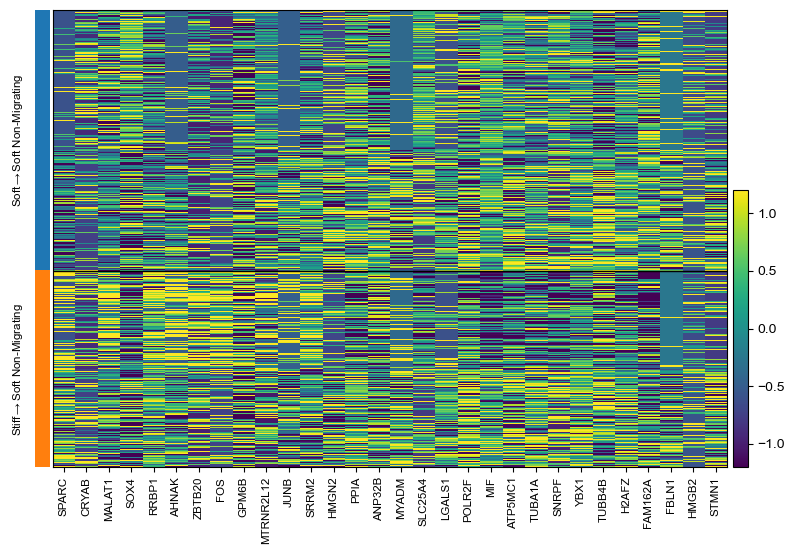

In [35]:
p_cutoff = 0.00005
lfc_cutoff = 0.35

axs = sc.pl.heatmap(sc.pp.scale(ad_combined[np.logical_or(ad_combined.obs['sample'] == 'StiffNon', ad_combined.obs['sample'] == 'SoftNon')], copy=True),
    var_names=top_vs_bottom.loc[(top_vs_bottom['FDR'] < p_cutoff) & (np.abs(top_vs_bottom['coef']) > lfc_cutoff), :].sort_values('coef').index,
    groupby='sample_name',
    vmax=1.2, vmin=-1.2,
    cmap='viridis',
    swap_axes=False,
    show = False
    #dendrogram=True
)
axs['groupby_ax'].set_yticks(axs['groupby_ax'].get_yticks(), axs['groupby_ax'].get_yticklabels(), rotation=90, ha='right', va='center')
axs['groupby_ax'].set_ylabel('')
#plt.savefig('top_vs_bottom_combined_heatmap.svg',  bbox_inches='tight')


## Stiff Mi vs Stiff Non

In [36]:
p_cutoff = 0.00005
lfc_cutoff = 0.5

stiffmi_vs_stiffnon.loc[(stiffmi_vs_stiffnon['FDR'] < p_cutoff) & (np.abs(stiffmi_vs_stiffnon['coef']) > lfc_cutoff), :].sort_values('coef')

,Pr(>Chisq),coef,FDR
primerid,,,
SPARC,9.498045e-238,-1.641089,2.643306e-234
FOS,1.260342e-142,-1.047622,1.169177e-139
ATF3,2.701289e-108,-0.899163,1.073955e-105
AHNAK,5.725377e-88,-0.777830,1.138123e-85
RRBP1,1.847023e-122,-0.706366,1.028053e-119
VIM,2.789462e-92,-0.690091,6.469228e-90
FOSB,2.726790e-89,-0.670146,5.837427e-87
MALAT1,1.488410e-54,-0.660311,1.380749e-52
FSTL1,3.273066e-95,-0.633362,9.108943e-93


In [37]:
p_cutoff = 0.00005
lfc_cutoff = 0.5

softmi_vs_softnon.loc[(softmi_vs_softnon['FDR'] < p_cutoff) & (np.abs(softmi_vs_softnon['coef']) > lfc_cutoff), :].sort_values('coef')

,Pr(>Chisq),coef,FDR
primerid,,,
SOX4,2.300046e-107,-0.716407,6.401029e-104
VEGFA,7.037469e-76,-0.655903,2.448160e-73
CRYAB,8.355626e-94,-0.614168,7.751236e-91
DDIT4,5.103632e-58,-0.509185,7.475477e-56
TUBB4B,1.295397e-60,0.507243,2.253182e-58
H2AFZ,9.864489e-45,0.507420,7.224441e-43
HMGB2,1.464701e-41,0.510001,9.942106e-40
STMN1,2.065031e-56,0.542807,2.736658e-54
CALM1,1.485004e-87,0.576843,6.887946e-85


In [38]:
p_cutoff = 0.00005
lfc_cutoff = 0.6

stiffmi_sig = stiffmi_vs_stiffnon.loc[(stiffmi_vs_stiffnon['FDR'] < p_cutoff) & (np.abs(stiffmi_vs_stiffnon['coef']) > lfc_cutoff)]
softmi_sig = softmi_vs_softnon.loc[(softmi_vs_softnon['FDR'] < p_cutoff) & (np.abs(softmi_vs_softnon['coef']) > 0.5)]

unqiue_migration_interface = stiffmi_sig.loc[~stiffmi_sig.index.isin(softmi_sig.index)].copy()
unqiue_migration_interface = unqiue_migration_interface.sort_values('coef')
unqiue_migration_interface


,Pr(>Chisq),coef,FDR
primerid,,,
SPARC,9.498045e-238,-1.641089,2.643306e-234
FOS,1.260342e-142,-1.047622,1.169177e-139
ATF3,2.701289e-108,-0.899163,1.073955e-105
AHNAK,5.725377e-88,-0.777830,1.138123e-85
RRBP1,1.847023e-122,-0.706366,1.028053e-119
VIM,2.789462e-92,-0.690091,6.469228e-90
FOSB,2.726790e-89,-0.670146,5.837427e-87
MALAT1,1.488410e-54,-0.660311,1.380749e-52
FSTL1,3.273066e-95,-0.633362,9.108943e-93


In [39]:
stiffmi_vs_stiffnon.loc['LGALS1']

Pr(>Chisq)    1.819589e-26
coef          3.245647e-01
FDR           3.956184e-25
Name: LGALS1, dtype: float64

/stor/home/tms4478/miniconda3/envs/scrna/lib/python3.10/site-packages/scanpy/plotting/_dotplot.py:168: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  obs_bool.groupby(level=0).sum() / obs_bool.groupby(level=0).count()
/stor/home/tms4478/miniconda3/envs/scrna/lib/python3.10/site-packages/scanpy/plotting/_dotplot.py:178: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  dot_color_df = self.obs_tidy.groupby(level=0).mean()
/stor/home/tms4478/miniconda3/envs/scrna/lib/python3.10/site-packages/scanpy/plotting/_dotplot.py:747: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be igno

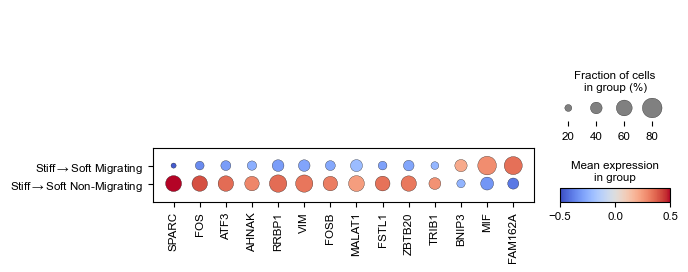

In [40]:
p_cutoff = 0.00005
lfc_cutoff = 0.6

axs= sc.pl.dotplot(
    sc.pp.scale(ad_combined[np.logical_or(ad_combined.obs['sample'] == 'StiffMi', ad_combined.obs['sample'] == 'StiffNon')], copy=True),
    #ad_hk177[np.logical_or(ad_hk177.obs['sample'] == 'StiffNon', ad_hk177.obs['sample'] == 'SoftNon')],
    var_names=unqiue_migration_interface.loc[(unqiue_migration_interface['FDR'] < p_cutoff) & (np.abs(unqiue_migration_interface['coef']) > lfc_cutoff), :].sort_values('coef').index,
    groupby='sample_name',
    vmax=0.5, vmin=-0.5,
    cmap='coolwarm',
    swap_axes=False,
    dendrogram=True,
    #save='stiffnon_vs_softnon_hk177_dotplot.svg'
    show=False
)
#plt.savefig('combined_unqiue_stifness_genes_dotplot.svg',  bbox_inches='tight')

In [41]:
['#440154ff','#22a884ff','#b22222','#4169e1']

['#440154ff', '#22a884ff', '#b22222', '#4169e1']

/stor/home/tms4478/miniconda3/envs/scrna/lib/python3.10/site-packages/scanpy/plotting/_anndata.py:839: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.violinplot(
/stor/home/tms4478/miniconda3/envs/scrna/lib/python3.10/site-packages/scanpy/plotting/_anndata.py:839: FutureWarning: 

The `scale` parameter has been renamed and will be removed in v0.15.0. Pass `density_norm='width'` for the same effect.
  ax = sns.violinplot(
/stor/home/tms4478/miniconda3/envs/scrna/lib/python3.10/site-packages/scanpy/plotting/_anndata.py:839: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.violinplot(
/stor/home/tms4478/miniconda3/envs/scrna/lib/python3.10/site-packages/scanpy/plotting/_anndata.py:839: FutureWarning: 


IndexError: index 3 is out of bounds for axis 0 with size 3

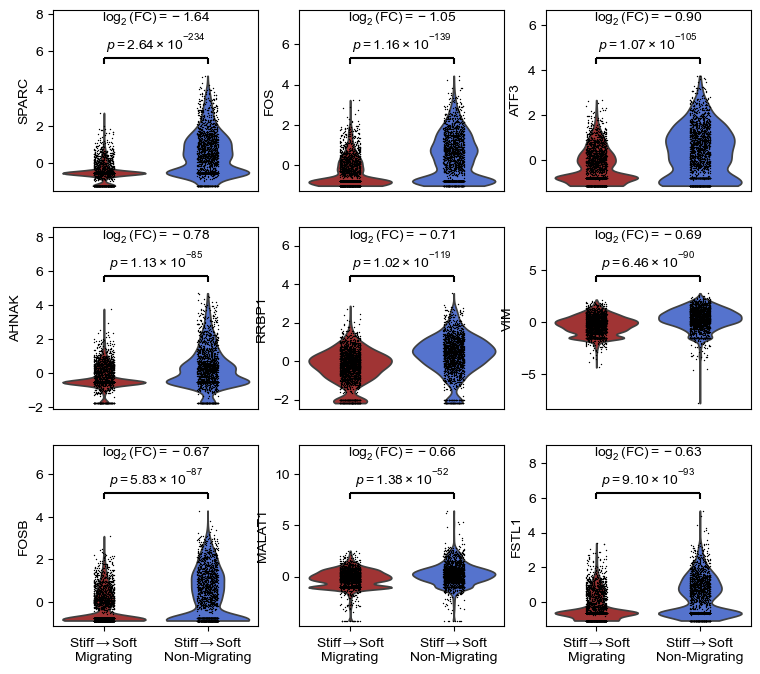

In [42]:
fig, axes = plt.subplots(3, 3, figsize=(9, 8))

for i, gene in enumerate(unqiue_migration_interface.index):
    ax = axes[i//3, i%3]

    sc.pl.violin(
        sc.pp.scale(ad_combined[np.logical_or(ad_combined.obs['sample'] == 'StiffMi', ad_combined.obs['sample'] == 'StiffNon')], copy=True),
        keys=gene,
        groupby="sample_name",
        ax=ax,
        palette= ['#b22222','#4169e1'],
        show=False,
    )

    if i < 6:
        ax.set_xticks([])
    else:
        ax.set_xticklabels([label.get_text().replace('t ', 't\n') for label in ax.get_xticklabels()])
    ax.set_xlabel("")

    lfc = unqiue_migration_interface.at[gene, 'coef']
    lfc = f'{lfc:.2f}'
    p = unqiue_migration_interface.at[gene, 'FDR']
    p = str(p).split('e')[0][:4]+' \\times 10^{'+str(p).split('e')[1]+'}'

    # make significance bars
    ymin = ax.get_ylim()[0]
    ymax = ax.get_ylim()[1]
    ax.hlines(ymax+(ymax-ymin)*0.1, 0, 1, colors='black')
    ax.vlines([0, 1], ymax+(ymax-ymin)*0.05, ymax+(ymax-ymin)*0.1, colors='black')
    ax.text(0.5, ymax+(ymax-ymin)*0.12, 
            f'$\log_2(\\text{{FC}})={lfc}$\n$p={p}$', 
            ha='center', va='bottom'
        )
    ax.set_ylim([ymin, ymax+(ymax-ymin)*0.5])

plt.tight_layout()
plt.savefig('figures/stiffmi_v_stiffnon_combined_genes.svg',  bbox_inches='tight')
plt.show()

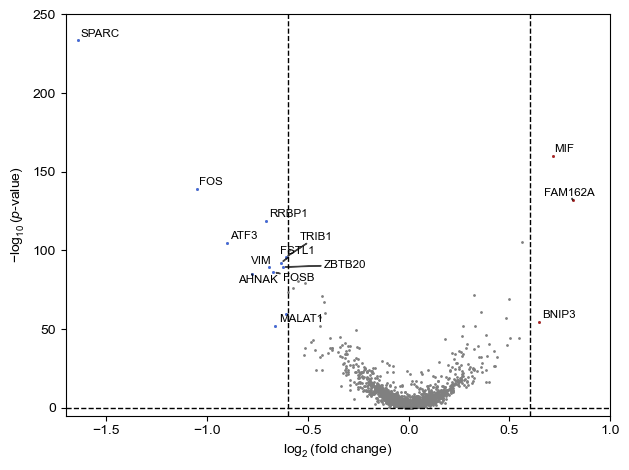

In [ ]:
lfc_cutoff=0.6
coef =0.00005

anns1 =[]

plt.scatter(
    stiffmi_vs_stiffnon['coef'],
    -np.log10(stiffmi_vs_stiffnon['FDR']),
    s=1, color='grey'
)

for gene in stiffmi_vs_stiffnon.index:
    if stiffmi_vs_stiffnon.loc[gene, 'coef'] > lfc_cutoff:
        plt.scatter(
            stiffmi_vs_stiffnon.loc[gene, 'coef'],
            -np.log10(stiffmi_vs_stiffnon.loc[gene, 'FDR']),
            color='firebrick', s=1
        )
    if stiffmi_vs_stiffnon.loc[gene, 'coef'] < -lfc_cutoff:
        plt.scatter(
            stiffmi_vs_stiffnon.loc[gene, 'coef'],
            -np.log10(stiffmi_vs_stiffnon.loc[gene, 'FDR']),
            color='royalblue', s=1
        )

for gene in unqiue_migration_interface.index:
        anns1.append(plt.text(
            stiffmi_vs_stiffnon.loc[gene, 'coef'],
            -np.log10(stiffmi_vs_stiffnon.loc[gene, 'FDR']),
            gene, fontweight='regular', size = 'small'
        ))

adjust_text(anns1, arrowprops=dict(linewidth=1, color='black', alpha=0.7))
plt.ylim(-5,250)
plt.ylabel('$-\log_{10}(p$-value$)$')
plt.xlabel('$\\log_2($fold change$)$')
plt.xlim(-1.7, 1)
plt.vlines([-lfc_cutoff, lfc_cutoff], plt.ylim()[0], plt.ylim()[1], color='black', linestyles='--', alpha=1., linewidth=1)
plt.hlines(p_cutoff, color='black', xmin=-1.7,xmax=1, linestyles='--', alpha=1., linewidth=1)

plt.tight_layout()
plt.savefig('figures/combined_stiffmi_vs_soft_unqiue_volcano.svg', bbox_inches='tight')
plt.show()

In [ ]:
lfc_cutoff=0.5
coef =0.00005

fig, axs = plt.subplots(1, 2, figsize=(8, 4))
axs[0].scatter(
    stiffmi_vs_stiffnon['coef'],
    -np.log10(stiffmi_vs_stiffnon['FDR']),
    s=1, color='grey'
)

axs[1].scatter(
    misubp_vs_nonmisubp['coef'],
    -np.log10(misubp_vs_nonmisubp['FDR']),
    s=1, color='grey'
)

axs[0].set_ylabel('$-\log_{10}(p$-value$)$')

axs[0].set_xlim(-1*1.1, 1*1.1)
axs[1].set_xlim(-1*1.1, 1*1.1)

for ax in axs:
    ax.set_xlabel('$\\log_2($fold change$)$')
    ax.set_ylim((0, ax.get_ylim()[1]))
    ax.vlines([-lfc_cutoff, lfc_cutoff], ax.get_ylim()[0], ax.get_ylim()[1], color='black', linestyles='--', alpha=1., linewidth=1)
    ax.hlines(p_cutoff, ax.get_xlim()[0], ax.get_xlim()[1], color='black', linestyles='--', alpha=1., linewidth=1)

axs[0].set_title('HK177 & GS54 Migrating Cells', fontweight='bold')
axs[1].set_title('Invasive Subpopulation of HK177', fontweight='bold')

anns1 = []
anns2 = []

for gene in stiffmi_vs_stiffnon.index:
    if stiffmi_vs_stiffnon.loc[gene, 'coef'] > lfc_cutoff:
        axs[0].scatter(
            stiffmi_vs_stiffnon.loc[gene, 'coef'],
            -np.log10(stiffmi_vs_stiffnon.loc[gene, 'FDR']),
            color='firebrick', s=1
        )
    if stiffmi_vs_stiffnon.loc[gene, 'coef'] < -lfc_cutoff:
        axs[0].scatter(
            stiffmi_vs_stiffnon.loc[gene, 'coef'],
            -np.log10(stiffmi_vs_stiffnon.loc[gene, 'FDR']),
            color='royalblue', s=1
        )
for gene in misubp_vs_nonmisubp.index:
    if misubp_vs_nonmisubp.loc[gene, 'coef'] > lfc_cutoff:
        axs[1].scatter(
            misubp_vs_nonmisubp.loc[gene, 'coef'],
            -np.log10(misubp_vs_nonmisubp.loc[gene, 'FDR']),
            color='firebrick', s=1
        )
    if misubp_vs_nonmisubp.loc[gene, 'coef'] < -lfc_cutoff:
        axs[1].scatter(
            misubp_vs_nonmisubp.loc[gene, 'coef'],
            -np.log10(misubp_vs_nonmisubp.loc[gene, 'FDR']),
            color='royalblue', s=1
        )

for gene in genes_of_intrest.index:
    axs[0].scatter(
        stiffmi_vs_stiffnon.loc[gene, 'coef'],
        -np.log10(stiffmi_vs_stiffnon.loc[gene, 'FDR']),
        color='black', s=5
    )
    axs[1].scatter(
        misubp_vs_nonmisubp.loc[gene, 'coef'],
        -np.log10(misubp_vs_nonmisubp.loc[gene, 'FDR']),
        color='black', s=5
    )
        

adjust_text(anns1, arrowprops=dict(linewidth=1, color='black', alpha=0.7), ax=axs[0])
adjust_text(anns2, arrowprops=dict(linewidth=1, color='black', alpha=0.7), ax=axs[1])

plt.savefig('figures/LGALS1_volcanoplot_subpop-combinedsamples.svg', bbox_inches='tight')

## Stiff Mi vs Soft Mi

In [ ]:
stiffmi_vs_softmi.loc[(stiffmi_vs_softmi['FDR'] < p_cutoff) & (np.abs(stiffmi_vs_softmi['coef']) > 0.25), :].sort_values('coef')

,Pr(>Chisq),coef,FDR
primerid,,,


## Combine datasets for IPA analysis

In [ ]:
combined_MAST_analysis = stiff_vs_soft[['coef','FDR']].merge(
    softmi_vs_softnon[['coef','FDR']],
    left_index=True, right_index=True, how='outer', suffixes=('_stiff_vs_soft', '_softmi_vs_softnon')
).merge(
    stiffmi_vs_softmi[['coef','FDR']],
    left_index=True, right_index=True, how='outer',
).merge(
    stiffmi_vs_stiffnon[['coef','FDR']],
    left_index=True, right_index=True, how='outer', suffixes=('_stiffmi_vs_softmi', '_stiffmi_vs_stiffnon')
).merge(
    stiffnon_vs_softnon[['coef','FDR']],
    left_index=True, right_index=True, how='outer',
).merge(
    top_vs_bottom[['coef','FDR']],
    left_index=True, right_index=True, how='outer', suffixes=('_stiffnon_vs_softnon', '_top_vs_bottom')
)

In [ ]:
combined_MAST_analysis.to_csv('combined_MAST_DEG.csv')


# Pathway Analysis

### Load in functions

In [ ]:
class IPA:
    def __init__(self, filepath: str, molecules_filepath=None):
        self.filepath = filepath
        self.pathways = None
        self.upstream_regulators = None
        self.causal_networks = None
        self.regulator_effects = None
        self.analysis_molecules = None
        self.molecules = pd.DataFrame()
        
        self._parse_file()

        if molecules_filepath:
            self.add_molecules(molecules_filepath)

    def __repr__(self):
        return f'IPA Analysis Result with:\n\t{self.pathways.shape[0]} pathways\n\t{self.upstream_regulators.shape[0]} upstream regulators\n\t{self.causal_networks.shape[0]} causal networks\n\t{self.regulator_effects.shape[0]} regulator effects\n\t{self.analysis_molecules.shape[0]} analysis-ready molecules\n\t{self.molecules.shape[0]} molecules'

    def _extract_table(self, lines, start_header, end_condition):
        table_lines = []
        in_table = False

        for line in lines:
            if not in_table and line.startswith(start_header):
                in_table = True
                continue  # skip header line itself

            if in_table:
                if end_condition(line):
                    break
                table_lines.append(line)

        if not table_lines:
            return None

        table_str = "\n".join(table_lines).strip()
        df = pd.read_table(StringIO(table_str), sep="\t", index_col=False)
        df.columns = df.columns.str.strip()
        return df

    def _parse_file(self):
        with open(self.filepath, "r", encoding="utf-8", errors="ignore") as f:
            lines = [line.rstrip("\n") for line in f]

        try:
            self.pathways = self._extract_table(
                lines,
                "Canonical Pathways for",
                lambda l: l.strip() == ""
            )
            self.pathways = self.pathways.set_index('Ingenuity Canonical Pathways')
        except pd.errors.EmptyDataError:
            self.pathways = pd.DataFrame()

        try:
            self.upstream_regulators = self._extract_table(
                lines,
                "Upstream Regulators for",
                lambda l: l.strip() == ""
            )
        except pd.errors.EmptyDataError:
            self.upstream_regulators = pd.DataFrame()

        try:
            self.causal_networks = self._extract_table(
                lines,
                "Causal Networks for",
                lambda l: l.strip() == ""
            )
        except pd.errors.EmptyDataError:
            self.causal_networks = pd.DataFrame()

        try:
            self.regulator_effects = self._extract_table(
                lines,
                "Regulator Effects for",
                lambda l: l.startswith("Networks for")
            )
        except pd.errors.EmptyDataError:
            self.regulator_effects = pd.DataFrame()

        try:
            self.analysis_molecules = self._extract_table(
                lines,
                "Analysis Ready Molecules for",
                lambda l: l.strip() == ""
            )
        except pd.errors.EmptyDataError:
            self.analysis_molecules = pd.DataFrame()

    def add_molecules(self, filepath):
        self.molecules = pd.read_table(filepath, header=1, index_col=0)

    def get_pathways(self, min_p = 0., min_abs_z=None, min_z=None, max_z=None, min_ratio=0., search_genes_any=[], search_genes_all=[], non_nan=False, sort_values=None):
        mask = (self.pathways['-log(p-value)'] >= min_p) & \
            (self.pathways['Ratio'] >= min_ratio)

        if min_abs_z:
            mask = mask & (np.abs(self.pathways['zScore']) >= min_abs_z) 

        if min_z:
            mask = mask & (self.pathways['zScore'] >= min_z)

        if max_z:
            mask = mask & (self.pathways['zScore'] <= max_z)

        if non_nan:
            mask = mask & ~np.any(pd.isna(self.pathways), axis=1)

        if isinstance(search_genes_any, str):
            mask = mask & self.pathways['Molecules'].str.contains(search_genes_any)
        elif len(search_genes_any) > 0:
            np.any([self.pathways['Molecules'].str.contains(gene) for gene in search_genes_any], axis=0)

        if isinstance(search_genes_all, str):
            mask = mask & self.pathways['Molecules'].str.contains(search_genes_all)
        elif len(search_genes_all) > 0:
            np.all([self.pathways['Molecules'].str.contains(gene) for gene in search_genes_all], axis=0)

        if sort_values:
            return self.pathways.loc[mask, :].sort_values(sort_values, ascending=False)
        else:
            return self.pathways.loc[mask, :]
        
    def get_molecules(self, min_lfc=-np.inf, max_lfc=np.inf, min_abs_lfc=0, max_p=1., locations=None, types=None, sort_values=None):
        mask = (self.molecules['Expr Log Ratio'] <= max_lfc) & \
            (self.molecules['Expr Log Ratio'] >= min_lfc) & \
            (np.abs(self.molecules['Expr Log Ratio']) >= min_abs_lfc) & \
            (self.molecules['Expr p-value'] <= max_p)
            
        if locations:
            mask = mask & np.isin(self.molecules['Location'], locations)

        if types:
            mask = mask & np.isin(self.molecules['Type(s)'], types)

        
        if sort_values:
            return self.molecules.loc[mask, :].sort_values(sort_values)
        else:
            return self.molecules.loc[mask, :]

In [ ]:
def paths_barplot(paths_df, title=None, sig_line=True, cbar_height=0.3, cmap='coolwarm', ax=None, rename_dict={}):
    import matplotlib.pyplot as plt
    from matplotlib.cm import ScalarMappable
    from matplotlib.colors import Normalize

    if not ax:
        fig, axs = plt.subplots(1, 2, figsize=(6, paths_df.shape[0]/3+0.2), gridspec_kw={'width_ratios': [20, 1]})
    else:
        axs = [ax]

    ps = 10**(paths_df['-log(p-value)'])
    zs = paths_df['zScore']
    max_z = np.max(np.abs(zs))
    zs_n = (zs/max_z)/2+0.5

    axs[0].barh(paths_df.index, ps, color=[plt.get_cmap(cmap)(z) for z in zs_n], linewidth=1, edgecolor='black')

    if sig_line:    
        axs[0].vlines(1/0.05, paths_df.shape[0]+1, -2, linestyles='--', color='black')

    axs[0].set_xscale('log')
    axs[0].set_xlim(1, axs[0].get_xlim()[1])
    axs[0].set_xticklabels([l.get_text().replace('10^{', '10^{-').replace('10^{-0}', '10^{0}') for l in axs[0].get_xticklabels()])
    labels = axs[0].get_yticklabels()
    for i in range(len(labels)):
        if labels[i].get_text() in rename_dict.keys():
            labels[i].set_text(rename_dict[labels[i].get_text()])
    axs[0].set_yticklabels(labels)
    axs[0].set_xlabel('$p$-value')

    axs[0].yaxis.set_inverted(True)
    axs[0].set_ylim(paths_df.shape[0], -1)

    if title:
        axs[0].set_title(title, fontweight='bold')
    
    if not ax:
        fig.colorbar(ScalarMappable(norm=Normalize(vmin=-max_z, vmax=max_z), cmap=cmap), cax=axs[1])
        cb_pos = axs[1].get_position()
        axs[1].set_position([cb_pos.x0-0.05, (cb_pos.y0+cb_pos.height/2)-(cbar_height/2), cb_pos.width, cbar_height])
        axs[1].set_title('$Z$-score', fontsize='medium', ha='left')
        #plt.tight_layout()

    return paths_df.index

In [ ]:
def paths_barplot_shape(paths_df, title=None, sig_line=True, cbar_height=0.3, cmap='coolwarm', ax=None, rename_dict={}):
    import matplotlib.pyplot as plt
    from matplotlib.cm import ScalarMappable
    from matplotlib.colors import Normalize

    if not ax:
        fig, axs = plt.subplots(1, 2, figsize=(4, paths_df.shape[0]/1+0.1), gridspec_kw={'width_ratios': [10, 1]})
    else:
        axs = [ax]

    ps = 10**(paths_df['-log(p-value)'])
    zs = paths_df['zScore']
    max_z = np.max(np.abs(zs))
    zs_n = (zs/max_z)/2+0.5

    axs[0].barh(paths_df.index, ps, color=[plt.get_cmap(cmap)(z) for z in zs_n], linewidth=1, edgecolor='black')

    if sig_line:    
        axs[0].vlines(1/0.05, paths_df.shape[0]+1, -2, linestyles='--', color='black')

    axs[0].set_xscale('log')
    axs[0].set_xlim(1, axs[0].get_xlim()[1])
    axs[0].set_xticklabels([l.get_text().replace('10^{', '10^{-').replace('10^{-0}', '10^{0}') for l in axs[0].get_xticklabels()])
    labels = axs[0].get_yticklabels()
    for i in range(len(labels)):
        if labels[i].get_text() in rename_dict.keys():
            labels[i].set_text(rename_dict[labels[i].get_text()])
    axs[0].set_yticklabels(labels)
    axs[0].set_xlabel('$p$-value')

    axs[0].yaxis.set_inverted(True)
    axs[0].set_ylim(paths_df.shape[0], -1)

    if title:
        axs[0].set_title(title, fontweight='bold')
    
    if not ax:
        fig.colorbar(ScalarMappable(norm=Normalize(vmin=-max_z, vmax=max_z), cmap=cmap), cax=axs[1])
        cb_pos = axs[1].get_position()
        axs[1].set_position([cb_pos.x0-0.05, (cb_pos.y0+cb_pos.height/2)-(cbar_height/2), cb_pos.width, cbar_height])
        axs[1].set_title('$Z$-score', fontsize='medium', ha='left')
        #plt.tight_layout()

    return paths_df.index

In [ ]:
def grouped_heatmap_lin(adata, ipa, groupby, pathways, lin_labels, colorbar_title='Mean scaled expression in group', figsize=None, textx=-1.1, texty=-1, bar_shorten_mult=0.01, bar_bend_length=0.1, xrot=45, **kwargs):
    _adata = adata.copy() # sc.pp.scale(adata, copy=True)

    gene_sets = {pathway:ipa.get_pathways().at[pathway.replace('\n', ' '), 'Molecules'] for pathway in pathways}
    gene_sets = {g:ipa.get_molecules().loc[gene_sets[g].split(','), 'Expr Log Ratio'].sort_values().index for g in gene_sets.keys()}

    xdim = np.sum([len(l) for l in lin_labels.values()])
    ydim = np.sum([len(g) for g in gene_sets.values()])

    heatmap = pd.DataFrame(index=np.concatenate(list(gene_sets.values())), columns=np.concatenate(list(lin_labels.values())), dtype=float)# np.zeros((ydim, xdim))
    
    x = 0
    for lin_label in lin_labels:
        for lin in lin_labels[lin_label]:
            y = 0
            for gene_set in gene_sets.keys():
                for gene in gene_sets[gene_set]:
                    #heatmap[y, x] = np.mean(ad[ad.obs[groupby] == cat, gene].X)
                    if gene in _adata.var_names:
                        heatmap.iloc[y,x] = np.mean(_adata[_adata.obs[groupby] == lin, gene].X)
                    else:
                        heatmap.iloc[y,x] = 0
                    y += 1
            x += 1

    heatmap = ((heatmap.T-heatmap.mean(axis=1))/heatmap.std(axis=1)).T

    fig, ax = plt.subplots(figsize=figsize)
    sns.heatmap(heatmap, ax=ax, cbar_kws=dict(label=colorbar_title), **kwargs)
    ax.set_xticklabels([])

    y = 0
    for gene_set in gene_sets.keys():
        dy = len(gene_sets[gene_set])
        ax.text(textx*1.1, dy/2+y, gene_set, rotation=90, va='center', ha='right', ma='center', fontweight='bold', size='small')
        lines = []
        lines.append(ax.vlines(textx, y+ydim*bar_shorten_mult, dy+y-ydim*bar_shorten_mult, color='black', linewidth=1))
        lines.append(ax.hlines(y+ydim*bar_shorten_mult, textx, textx*(1-bar_bend_length), color='black', linewidth=1))
        lines.append(ax.hlines(dy+y-ydim*bar_shorten_mult, textx, textx*(1-bar_bend_length), color='black', linewidth=1))
        for line in lines:
            line.set_clip_on(False)
        y += dy
        if y != ydim:
            ax.hlines(y, 0, xdim, color='black', linewidth=1)

    x = 0
    for lin_label in lin_labels.keys():
        dx = len(lin_labels[lin_label])
        ax.text(dx/2+x, texty*1.1, lin_label, va='bottom', ha='center', fontweight='bold')
        lines = []
        lines.append(ax.hlines(texty, x+xdim*bar_shorten_mult, dx+x-xdim*bar_shorten_mult, color='black', linewidth=1))
        lines.append(ax.vlines(x+xdim*bar_shorten_mult, texty, texty*(1-bar_bend_length), color='black', linewidth=1))
        lines.append(ax.vlines(dx+x-xdim*bar_shorten_mult, texty, texty*(1-bar_bend_length), color='black', linewidth=1))
        for line in lines:
            line.set_clip_on(False)
        x += dx
        if x != xdim:
            ax.vlines(dx, 0, ydim, color='black', linewidth=1)

### Load in Data

In [ ]:
IPA_softmi_vs_softnon= IPA('combined_analysis/summary/softmi_vs_softnon.txt', molecules_filepath='combined_analysis/molecules/softmi_vs_softnon.txt')
IPA_stiff_vs_soft= IPA('combined_analysis/summary/stiff_vs_soft.txt', molecules_filepath='combined_analysis/molecules/stiff_vs_soft.txt')
IPA_stiffmi_vs_softmi = IPA('combined_analysis/summary/stiffmi_vs_softmi.txt', molecules_filepath='combined_analysis/molecules/stiffmi_vs_softmi.txt')
IPA_stiffmi_vs_stiffnon= IPA('combined_analysis/summary/stiffmi_vs_stiffnon.txt', molecules_filepath='combined_analysis/molecules/stiffmi_vs_stiffnon.txt')
IPA_stiffnon_vs_softnon = IPA('combined_analysis/summary/stiffnon_vs_softnon.txt', molecules_filepath='combined_analysis/molecules/stiffnon_vs_softnon.txt')
IPA_top_vs_bottom = IPA('combined_analysis/summary/top_vs_bottom.txt', molecules_filepath='hk177/molecules/top_vs_bottom.txt')

In [ ]:
pathway_rename_dict = {
    'Regulation of Insulin-like Growth Factor (IGF) transport and uptake by IGFBPs':'Regulation of Insulin-like Growth\nFactor (IGF) transport and uptake by IGFBPs',
    'Sirtuin Signaling Pathway':'Sirtuin Signaling',
    'Metallothioneins bind metals':'Metallothioneins\nbind metals',
    'Integrin to Cytoskeleton Signaling Pathway': 'Integrin to Cytoskeleton\nSignaling' ,
    'Nuclear Cytoskeleton Signaling Pathway':'Nuclear Cytoskeleton\nSignaling' ,
    'Actin Cytoskeleton Signaling':'Actin Cytoskeleton\nSignaling',
    'Oxidative Phosphorylation':'Oxidative\nPhosphorylation',
    'Extracellular matrix organization': 'Extracellular matrix\norganization',
    'Collagen biosynthesis and modifying enzymes': 'Collagen\nbiosynthesis and\nmodifying enzymes',
    'Integrin cell surface interactions':'Integrin cell\nsurface interactions',
    'Assembly of collagen fibrils and other multimeric structures':'Assembly of\ncollagen fibrils\nand other\nmultimeric structures',
    'ROBO SLIT Signaling Pathway':'ROBO SLIT\nSignaling',
    'Signaling by ROBO receptors': 'Signaling by\nROBO receptors',
    'GAIT Translation Signaling Pathway':'GAIT Translation\nSignaling',
    'Cellular response to hypoxia':'Cellular response\nto hypoxia',
    'Remodeling of Epithelial Adherens Junctions':'Remodeling of\nEpithelial Adherens\nJunctions',
    'Actin Cytoskeleton Signaling':'Actin Cytoskeleton\nSignaling',
    'RHO GTPases Activate Formins':'RHO GTPases\nActivate Formins',
    'Regulation of Actin-based Motility by Rho': 'Regulation of\nActin-based\nMotility by Rho',
    'Degradation of beta-catenin by the destruction complex':'Degradation of\nbeta-catenin by the\ndestruction complex',
    'Signaling by Rho Family GTPases':'Signaling by\nRho Family GTPases',
    'ABRA Signaling Pathway': 'ABRA Signaling',
    'Asparagine N-linked glycosylation':'Asparagine N-linked\nglycosylation'
    }

## Stiffnon v Softnon

In [ ]:
IPA_stiffnon_vs_softnon.get_molecules(
    max_p=0.05,
    min_abs_lfc=0.2,
    sort_values='Expr Log Ratio'
).head(20)

,Entrez Gene Name,Gene Symbol - human (HUGO / HGNC / Entrez Gene),Expr Log Ratio,Expr p-value,Location,Type(s),Biomarker Application(s),Drug(s),Entrez Gene ID for Human,Entrez Gene ID for Mouse,Entrez Gene ID for Rat
Symbol,,,,,,,,,,,
DDIT4,DNA damage inducible transcript 4,DDIT4,-0.738,1.800000e-108,Cytoplasm,other,unspecified application,NaN,,,
VEGFA,vascular endothelial growth factor A,VEGFA,-0.717,1.000000e-63,Extracellular Space,growth factor,"diagnosis,efficacy,prognosis,safety,unspecifie...","aflibercept,aflibercept/bevacizumab,aflibercep...",,,
FAM162A,family with sequence similarity 162 member A,FAM162A,-0.558,3.600000e-62,Cytoplasm,other,NaN,NaN,,,
MIF,macrophage migration inhibitory factor,MIF,-0.539,6.660000e-111,Extracellular Space,cytokine,"diagnosis,prognosis,response to therapy",imalumab,,,
BNIP3,BCL2 interacting protein 3,BNIP3,-0.538,1.770000e-29,Cytoplasm,other,NaN,NaN,,,
TPT1,"tumor protein, translationally-controlled 1",TPT1,-0.486,3.820000e-80,Cytoplasm,other,NaN,NaN,,,
GAPDH,glyceraldehyde-3-phosphate dehydrogenase,GAPDH,-0.458,5.470000e-70,Cytoplasm,enzyme,"diagnosis,unspecified application",NaN,,,
PGK1,phosphoglycerate kinase 1,PGK1,-0.453,8.180000e-50,Cytoplasm,kinase,NaN,CBR-470-1,,,
EEF1G,eukaryotic translation elongation factor 1 gamma,EEF1G,-0.422,5.560000e-81,Cytoplasm,translation regulator,NaN,NaN,,,


/tmp/ipykernel_455970/3005380184.py:23: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[0].set_xticklabels([l.get_text().replace('10^{', '10^{-').replace('10^{-0}', '10^{0}') for l in axs[0].get_xticklabels()])
/tmp/ipykernel_455970/3005380184.py:28: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[0].set_yticklabels(labels)


Index(['Processing of Capped Intron-Containing Pre-mRNA',
       'Protein Ubiquitination Pathway', 'PTEN Regulation',
       'RNA Polymerase II Transcription',
       'Class I MHC mediated antigen processing and presentation', 'S Phase',
       'Chromatin modifying enzymes', 'Mitotic Metaphase and Anaphase',
       'Regulation of mRNA stability by proteins that bind AU-rich elements',
       'Mitotic G2-G2/M phases',
       ...
       'Virus Entry via Endocytic Pathways',
       'Factors involved in megakaryocyte development and platelet production',
       'XBP1(S) activates chaperone genes',
       'Melanocyte Development and Pigmentation Signaling',
       'Asparagine N-linked glycosylation', 'RHO GTPases activate CIT',
       'RHO GTPases Activate ROCKs', 'PAK Signaling',
       'Expression of BMAL (ARNTL), CLOCK, and NPAS2',
       'RNA polymerase II transcribes snRNA genes'],
      dtype='object', name='Ingenuity Canonical Pathways', length=141)

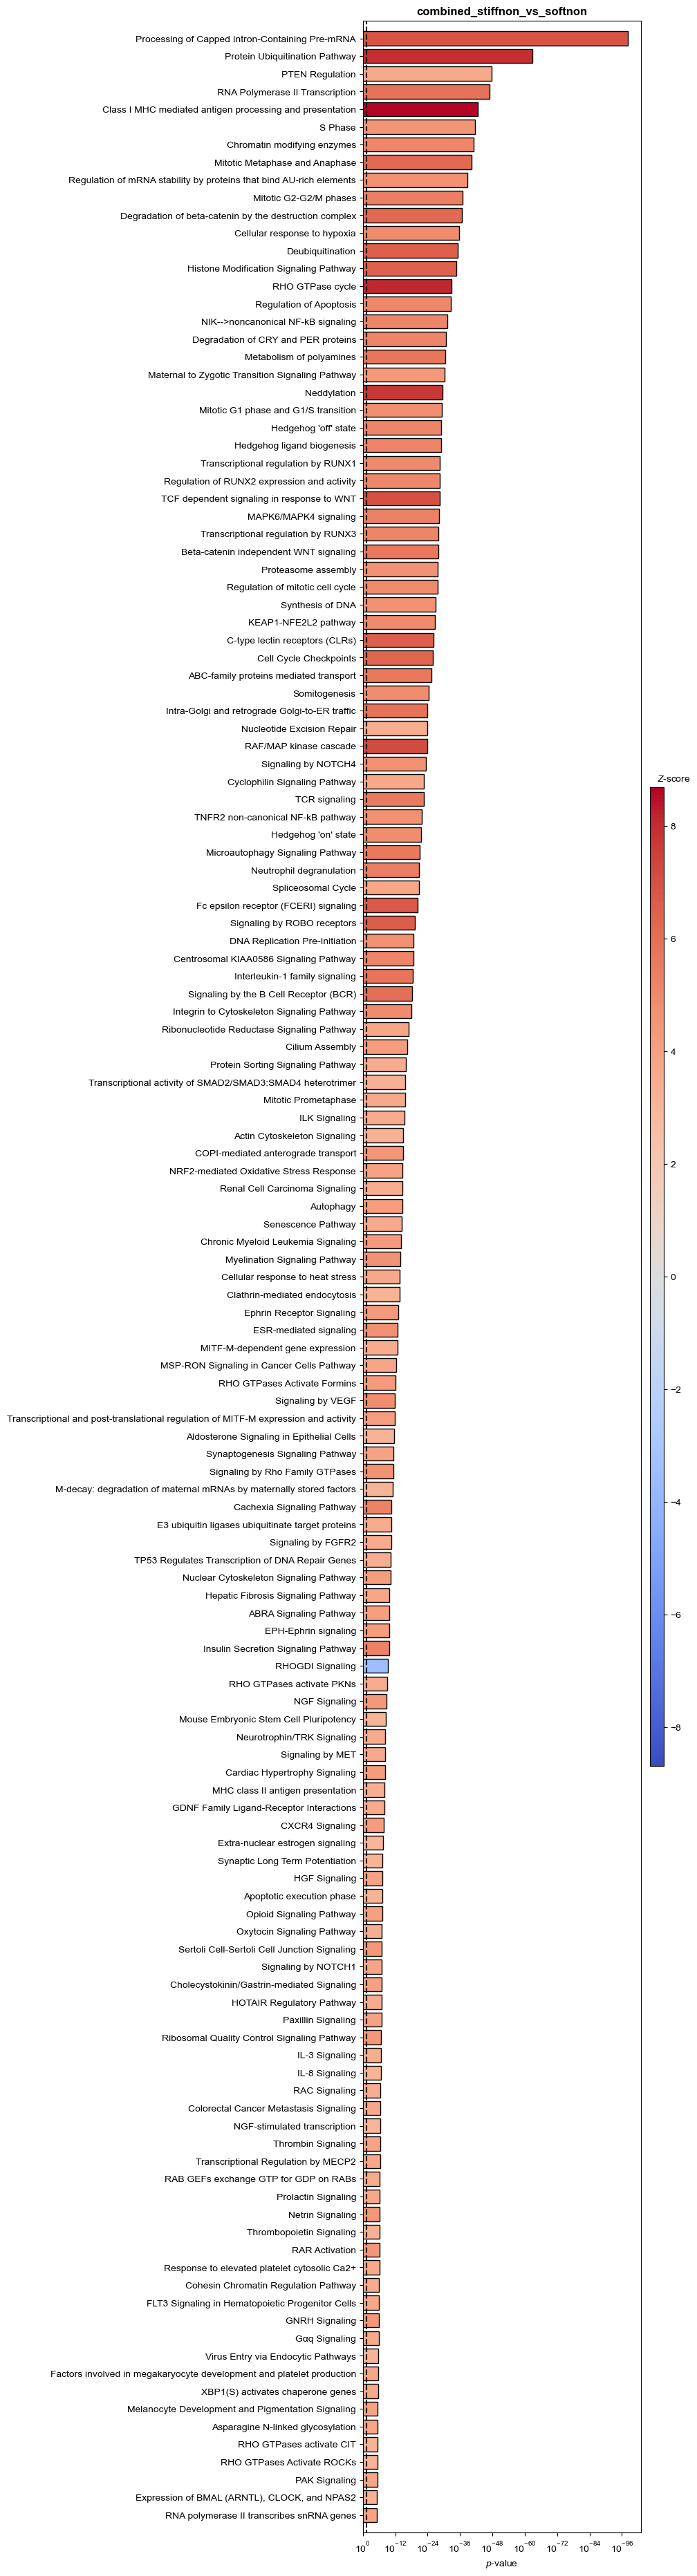

In [ ]:
paths_barplot(
    IPA_stiffnon_vs_softnon.get_pathways(
        min_p=-np.log10(0.000005),
        min_abs_z=3,
        non_nan=True,
        sort_values='-log(p-value)'
    ),
    title='combined_stiffnon_vs_softnon'
)

/tmp/ipykernel_455970/1554186587.py:23: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[0].set_xticklabels([l.get_text().replace('10^{', '10^{-').replace('10^{-0}', '10^{0}') for l in axs[0].get_xticklabels()])
/tmp/ipykernel_455970/1554186587.py:28: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[0].set_yticklabels(labels)


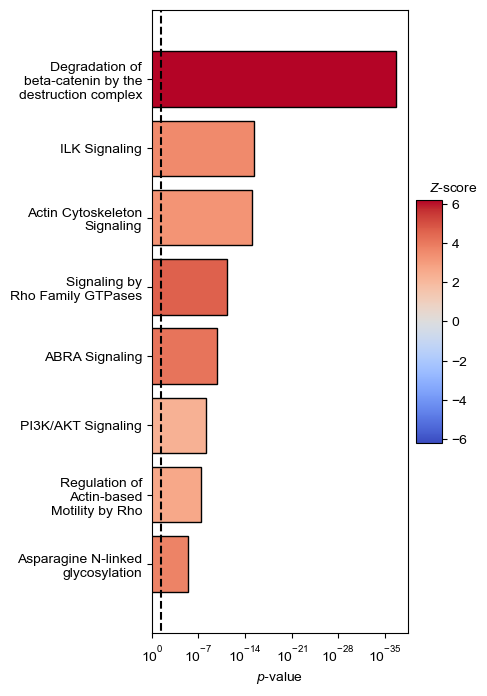

In [ ]:
paths_barplot_shape(
    IPA_stiffnon_vs_softnon.get_pathways(
        min_p=-np.log10(0.0005),
        min_abs_z=2,
        non_nan=True,
        sort_values='-log(p-value)'
    ).loc[['Degradation of beta-catenin by the destruction complex',
           'ILK Signaling',
           'Actin Cytoskeleton Signaling',
           'Signaling by Rho Family GTPases',
           'ABRA Signaling Pathway',
           'PI3K/AKT Signaling',
           'Regulation of Actin-based Motility by Rho',
           'Asparagine N-linked glycosylation'],:],
    rename_dict= pathway_rename_dict,
    title=''
)
plt.savefig('figures/combined_stiffnon_vs_softnon_pathways_shortened-long-2.svg', bbox_inches='tight')

/tmp/ipykernel_455970/3005380184.py:23: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[0].set_xticklabels([l.get_text().replace('10^{', '10^{-').replace('10^{-0}', '10^{0}') for l in axs[0].get_xticklabels()])
/tmp/ipykernel_455970/3005380184.py:28: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[0].set_yticklabels(labels)


Index(['Processing of Capped Intron-Containing Pre-mRNA',
       'Protein Ubiquitination Pathway', 'RNA Polymerase II Transcription',
       'Class I MHC mediated antigen processing and presentation',
       'Chromatin modifying enzymes', 'Mitotic G2-G2/M phases',
       'Degradation of beta-catenin by the destruction complex',
       'Cellular response to hypoxia', 'Deubiquitination',
       'Histone Modification Signaling Pathway',
       ...
       'Signaling by EGFR', 'Glioblastoma Multiforme Signaling',
       'Melanocyte Development and Pigmentation Signaling',
       'Asparagine N-linked glycosylation', 'RHO GTPases Activate ROCKs',
       'PAK Signaling', 'Cellular response to mitochondrial stress',
       'Expression of BMAL (ARNTL), CLOCK, and NPAS2',
       'RNA polymerase II transcribes snRNA genes', 'JAK/STAT Signaling'],
      dtype='object', name='Ingenuity Canonical Pathways', length=172)

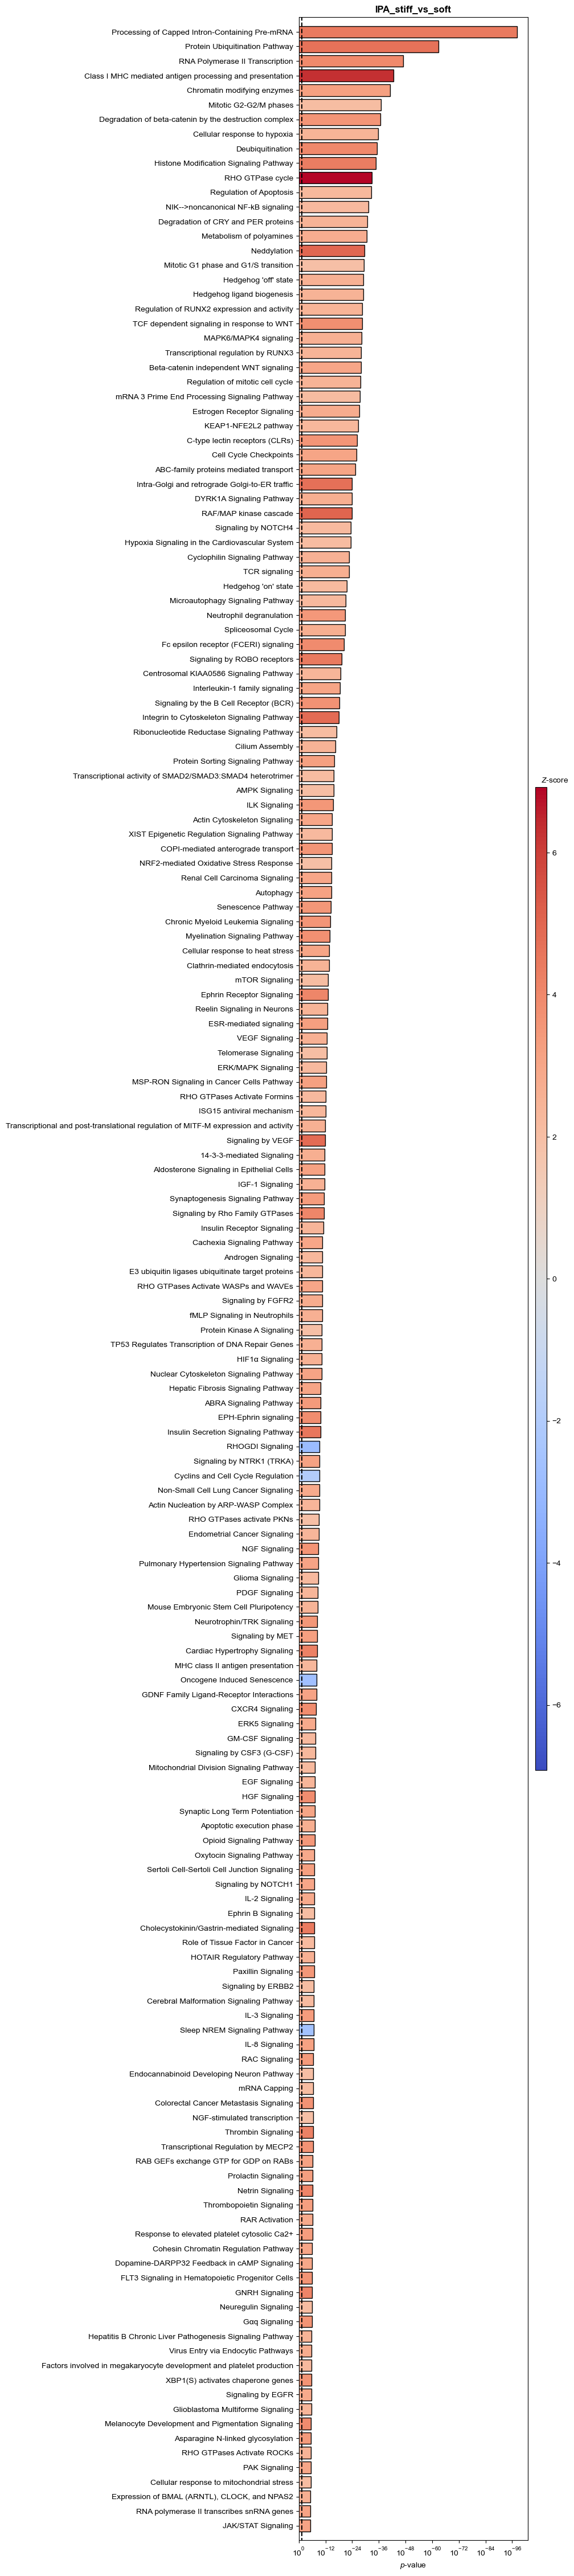

In [ ]:
IPA_stiff_vs_soft
paths_barplot(
    IPA_stiff_vs_soft.get_pathways(
        min_p=-np.log10(0.000005),
        min_abs_z=2,
        non_nan=True,
        sort_values='-log(p-value)'
    ),
    title='IPA_stiff_vs_soft'
)

In [ ]:
IPA_stiff_vs_soft.get_pathways(
        min_p=-np.log10(0.0000005),
        min_abs_z=3,
        non_nan=True,
        sort_values='-log(p-value)'
    ).index.to_list

<bound method IndexOpsMixin.tolist of Index(['Processing of Capped Intron-Containing Pre-mRNA',
       'Protein Ubiquitination Pathway', 'RNA Polymerase II Transcription',
       'Class I MHC mediated antigen processing and presentation',
       'Chromatin modifying enzymes',
       'Degradation of beta-catenin by the destruction complex',
       'Deubiquitination', 'Histone Modification Signaling Pathway',
       'RHO GTPase cycle', 'Neddylation',
       'TCF dependent signaling in response to WNT',
       'Beta-catenin independent WNT signaling',
       'C-type lectin receptors (CLRs)', 'Cell Cycle Checkpoints',
       'ABC-family proteins mediated transport', 'RAF/MAP kinase cascade',
       'Intra-Golgi and retrograde Golgi-to-ER traffic',
       'Neutrophil degranulation', 'Fc epsilon receptor (FCERI) signaling',
       'Signaling by ROBO receptors', 'Interleukin-1 family signaling',
       'Signaling by the B Cell Receptor (BCR)',
       'Integrin to Cytoskeleton Signaling Pathwa

## StiffMi vs Stiffnon

In [ ]:
IPA_stiffmi_vs_stiffnon.get_molecules(
    max_p=0.05,
    min_abs_lfc=0.2,
    sort_values='Expr Log Ratio'
).head(20)

,Entrez Gene Name,Gene Symbol - human (HUGO / HGNC / Entrez Gene),Expr Log Ratio,Expr p-value,Location,Type(s),Biomarker Application(s),Drug(s),Entrez Gene ID for Human,Entrez Gene ID for Mouse,Entrez Gene ID for Rat
Symbol,,,,,,,,,,,
SPARC,secreted protein acidic and cysteine rich,SPARC,-1.641,2.640000e-234,Extracellular Space,other,"disease progression,efficacy",NaN,,,
FOS,"Fos proto-oncogene, AP-1 transcription factor ...",FOS,-1.048,1.170000e-139,Nucleus,transcription regulator,"diagnosis,efficacy",NaN,,,
ATF3,activating transcription factor 3,ATF3,-0.899,1.070000e-105,Nucleus,transcription regulator,unspecified application,NaN,,,
AHNAK,AHNAK nucleoprotein,AHNAK,-0.778,1.140000e-85,Nucleus,other,NaN,NaN,79026,66395,191572
RRBP1,ribosome binding protein 1,RRBP1,-0.706,1.030000e-119,Cytoplasm,other,unspecified application,NaN,,,
VIM,vimentin,VIM,-0.690,6.470000e-90,Cytoplasm,other,"diagnosis,efficacy,prognosis,unspecified appli...",pritumumab,,,
FOSB,"FosB proto-oncogene, AP-1 transcription factor...",FOSB,-0.670,5.840000e-87,Nucleus,transcription regulator,NaN,NaN,,,
MALAT1,metastasis associated lung adenocarcinoma tran...,MALAT1,-0.660,1.380000e-52,Nucleus,other,NaN,NaN,,,
FSTL1,follistatin like 1,FSTL1,-0.633,9.110000e-93,Extracellular Space,other,NaN,NaN,,,


/tmp/ipykernel_455970/3005380184.py:23: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[0].set_xticklabels([l.get_text().replace('10^{', '10^{-').replace('10^{-0}', '10^{0}') for l in axs[0].get_xticklabels()])
/tmp/ipykernel_455970/3005380184.py:28: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[0].set_yticklabels(labels)


Index(['Class I MHC mediated antigen processing and presentation',
       'Histone Modification Signaling Pathway', 'RHO GTPase cycle',
       'Neddylation', 'TCF dependent signaling in response to WNT',
       'mRNA 3 Prime End Processing Signaling Pathway',
       'Oxidative Phosphorylation',
       'Intra-Golgi and retrograde Golgi-to-ER traffic',
       'Respiratory electron transport', 'Protein folding',
       'Chronic Myeloid Leukemia Signaling',
       'Neuron Navigator Signaling Pathway', 'Cristae formation',
       'CSDE1 Signaling Pathway', 'MSP-RON Signaling in Cancer Cells Pathway',
       'Mitochondrial protein import', 'Unfolded protein response',
       'Signaling by VEGF', 'Aldosterone Signaling in Epithelial Cells',
       'Granzyme A Signaling', 'Hepatic Fibrosis Signaling Pathway',
       'Mitophagy', 'Formation of ATP by chemiosmotic coupling',
       'Oncogene Induced Senescence', 'RHO GTPases activate IQGAPs',
       'HOTAIR Regulatory Pathway', 'Colorectal Cance

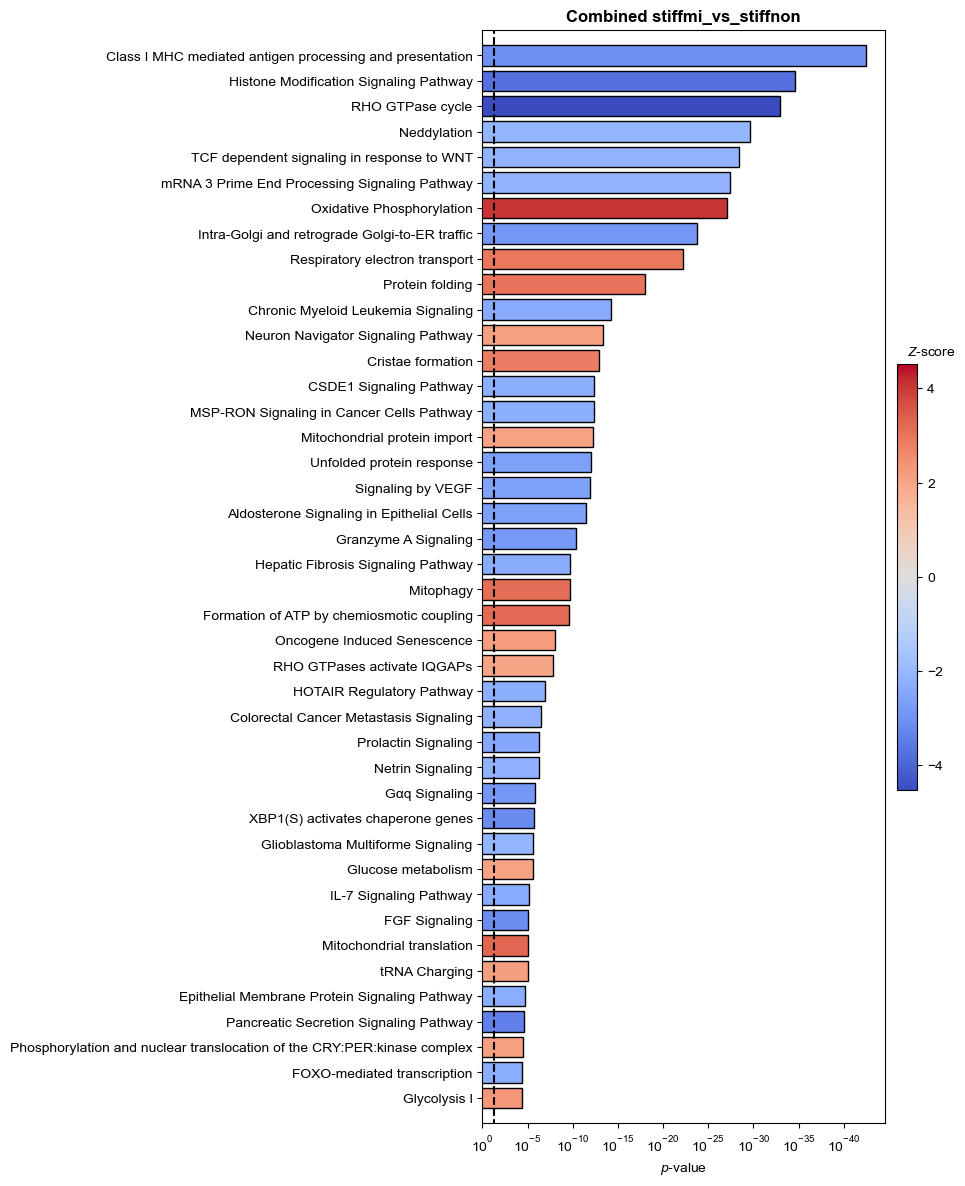

In [ ]:
paths_barplot(
    IPA_stiffmi_vs_stiffnon.get_pathways(
        min_p=-np.log10(0.00005),
        min_abs_z=2,
        non_nan=True,
        sort_values='-log(p-value)'
    ),
    title='Combined stiffmi_vs_stiffnon'
)

/tmp/ipykernel_455970/3005380184.py:23: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[0].set_xticklabels([l.get_text().replace('10^{', '10^{-').replace('10^{-0}', '10^{0}') for l in axs[0].get_xticklabels()])
/tmp/ipykernel_455970/3005380184.py:28: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[0].set_yticklabels(labels)


Index(['RHO GTPase cycle', 'RHO GTPases activate IQGAPs',
       'TCF dependent signaling in response to WNT', 'Signaling by VEGF',
       'MSP-RON Signaling in Cancer Cells Pathway',
       'Colorectal Cancer Metastasis Signaling',
       'Hepatic Fibrosis Signaling Pathway', 'FGF Signaling'],
      dtype='object', name='Ingenuity Canonical Pathways')

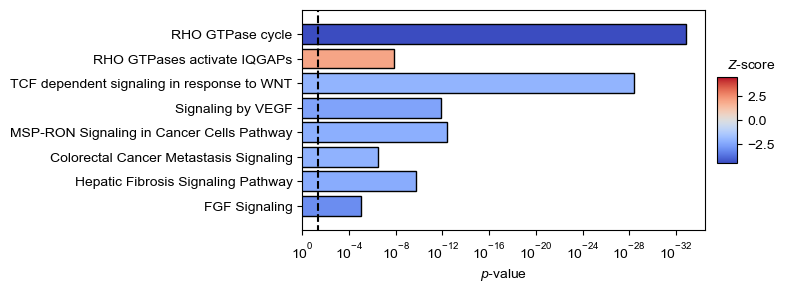

In [ ]:
paths_barplot(
    IPA_stiffmi_vs_stiffnon.get_pathways(
        min_p=-np.log10(0.00005),
        min_abs_z=2,
        non_nan=True,
        sort_values='-log(p-value)'
    ).loc[['RHO GTPase cycle',
           'RHO GTPases activate IQGAPs',
           'TCF dependent signaling in response to WNT',
           'Signaling by VEGF',
           'MSP-RON Signaling in Cancer Cells Pathway',
           'Colorectal Cancer Metastasis Signaling',
           'Hepatic Fibrosis Signaling Pathway',
           'FGF Signaling',
           ],:],
    rename_dict=pathway_rename_dict,
    title=''
)

/tmp/ipykernel_455970/3005380184.py:23: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[0].set_xticklabels([l.get_text().replace('10^{', '10^{-').replace('10^{-0}', '10^{0}') for l in axs[0].get_xticklabels()])
/tmp/ipykernel_455970/3005380184.py:28: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[0].set_yticklabels(labels)


Index(['Processing of Capped Intron-Containing Pre-mRNA',
       'Protein Ubiquitination Pathway', 'PTEN Regulation',
       'RNA Polymerase II Transcription',
       'Class I MHC mediated antigen processing and presentation', 'S Phase',
       'Chromatin modifying enzymes', 'Mitotic Metaphase and Anaphase',
       'Regulation of mRNA stability by proteins that bind AU-rich elements',
       'Mitotic G2-G2/M phases',
       ...
       'Complex III assembly', 'Glucose metabolism',
       'NoRC negatively regulates rRNA expression',
       'Regulation of TP53 Activity through Phosphorylation',
       'Melanocyte Development and Pigmentation Signaling',
       'Estrogen-Dependent Breast Cancer Signaling',
       'Asparagine N-linked glycosylation', 'Necroptosis Signaling Pathway',
       'RHO GTPases Activate ROCKs',
       'RNA polymerase II transcribes snRNA genes'],
      dtype='object', name='Ingenuity Canonical Pathways', length=163)

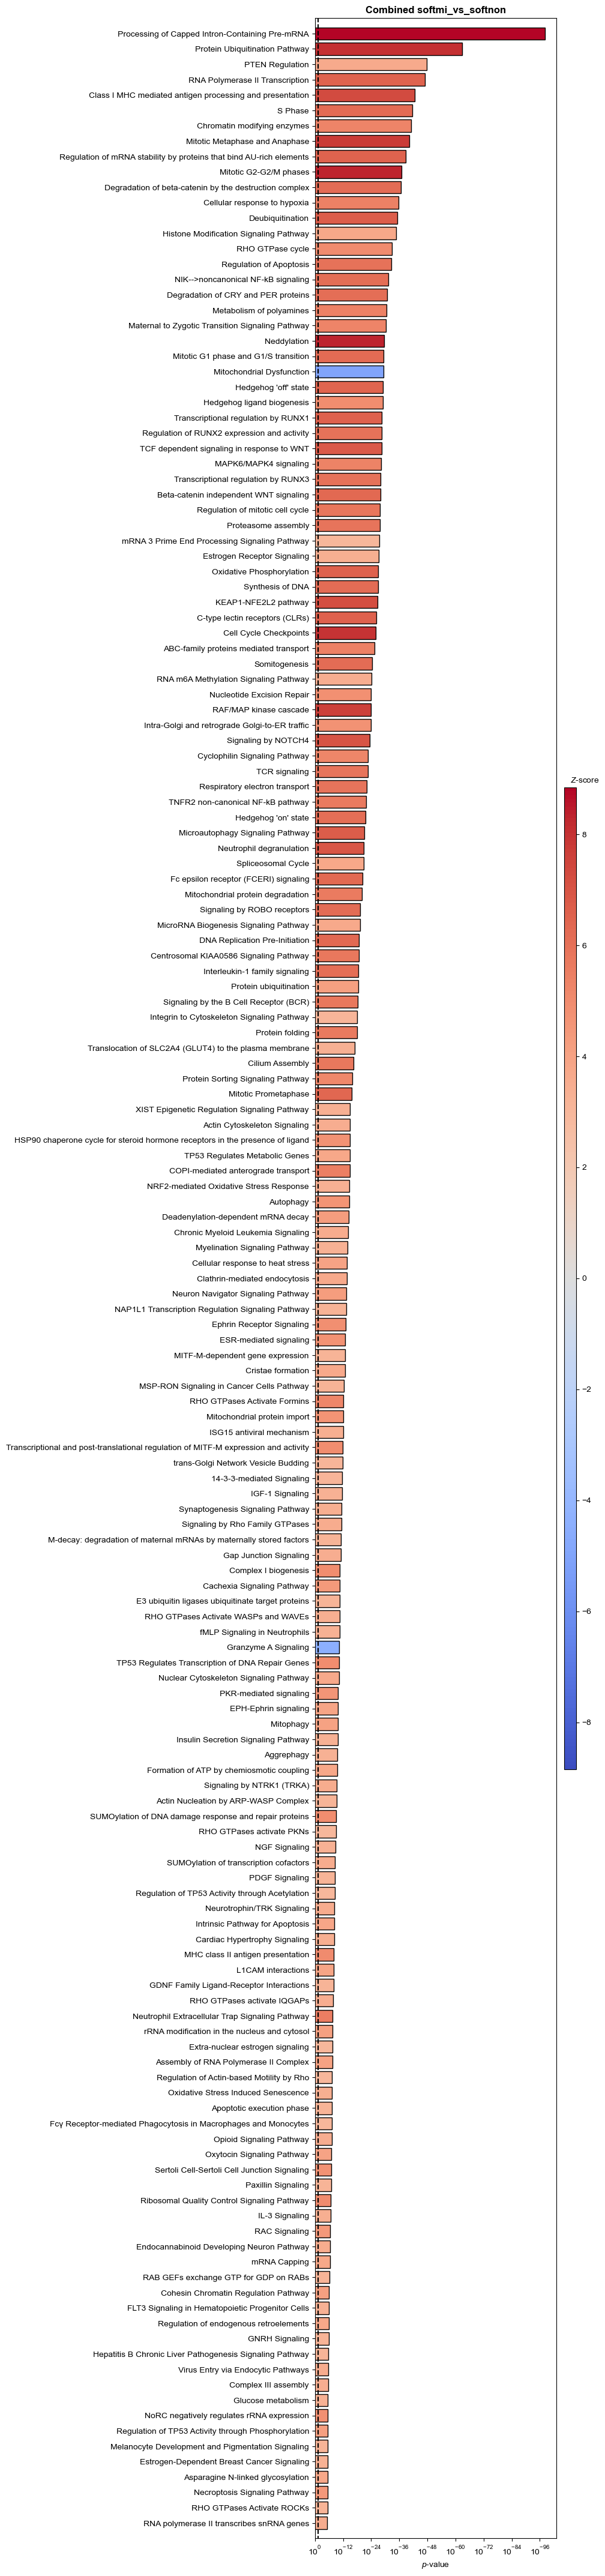

In [ ]:
paths_barplot(
    IPA_softmi_vs_softnon.get_pathways(
        min_p=-np.log10(0.000005),
        min_abs_z=3,
        non_nan=True,
        sort_values='-log(p-value)'
    ),
    title='Combined softmi_vs_softnon'
)